## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")
sns.set_context("notebook")

## Load Dataset

In [2]:
df = pd.read_csv(r'Salary_Dataset_DSL.csv')

df

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android
...,...,...,...,...,...,...,...,...
22765,4.7,Expert Solutions,Web Developer,200000,1,Bangalore,Full Time,Web
22766,4.0,Nextgen Innovation Labs,Web Developer,300000,1,Bangalore,Full Time,Web
22767,4.1,Fresher,Full Stack Web Developer,192000,13,Bangalore,Full Time,Web
22768,4.1,Accenture,Full Stack Web Developer,300000,7,Bangalore,Full Time,Web


## Basic Information from Dataset

In [3]:
df.shape

(22770, 8)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22770 entries, 0 to 22769
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Rating             22770 non-null  float64
 1   Company Name       22769 non-null  object 
 2   Job Title          22770 non-null  object 
 3   Salary             22770 non-null  int64  
 4   Salaries Reported  22770 non-null  int64  
 5   Location           22770 non-null  object 
 6   Employment Status  22770 non-null  object 
 7   Job Roles          22770 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 1.4+ MB


In [5]:
df.describe()

,Rating,Salary,Salaries Reported
count,22770.000000,2.277000e+04,22770.000000
mean,3.918213,6.953872e+05,1.855775
std,0.519675,8.843990e+05,6.823668
min,1.000000,2.112000e+03,1.000000
25%,3.700000,3.000000e+05,1.000000
50%,3.900000,5.000000e+05,1.000000
75%,4.200000,9.000000e+05,1.000000
max,5.000000,9.000000e+07,361.000000


In [6]:
df.describe(include = 'all')

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
count,22770.000000,22769,22770,2.277000e+04,22770.000000,22770,22770,22770
unique,NaN,11260,1080,NaN,NaN,10,4,11
top,NaN,Tata Consultancy Services,Software Development Engineer,NaN,NaN,Bangalore,Full Time,SDE
freq,NaN,271,2351,NaN,NaN,8264,20083,8183
mean,3.918213,NaN,NaN,6.953872e+05,1.855775,NaN,NaN,NaN
std,0.519675,NaN,NaN,8.843990e+05,6.823668,NaN,NaN,NaN
min,1.000000,NaN,NaN,2.112000e+03,1.000000,NaN,NaN,NaN
25%,3.700000,NaN,NaN,3.000000e+05,1.000000,NaN,NaN,NaN
50%,3.900000,NaN,NaN,5.000000e+05,1.000000,NaN,NaN,NaN
75%,4.200000,NaN,NaN,9.000000e+05,1.000000,NaN,NaN,NaN


## Data Cleaning

#### Check Missing Values

In [7]:
df.isnull().sum()

Rating               0
Company Name         1
Job Title            0
Salary               0
Salaries Reported    0
Location             0
Employment Status    0
Job Roles            0
dtype: int64

In [8]:
df.drop_duplicates()

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android
...,...,...,...,...,...,...,...,...
22765,4.7,Expert Solutions,Web Developer,200000,1,Bangalore,Full Time,Web
22766,4.0,Nextgen Innovation Labs,Web Developer,300000,1,Bangalore,Full Time,Web
22767,4.1,Fresher,Full Stack Web Developer,192000,13,Bangalore,Full Time,Web
22768,4.1,Accenture,Full Stack Web Developer,300000,7,Bangalore,Full Time,Web


In [9]:
df[df['Company Name'].isna()] ## identify the row with missing company name.

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
13760,4.0,NaN,Software Development Engineer,1188000,1,Bangalore,Full Time,SDE


## Outlier Detection & Removal

#### Visualize Salary Outliers

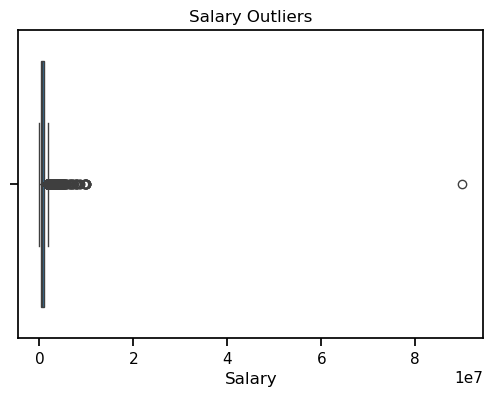

In [10]:
plt.figure(figsize=(6,4))
sns.boxplot(x = df['Salary'])

plt.title('Salary Outliers')
plt.show()

#### IQR (Interquartile Range) Method

In [58]:
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1


In [59]:
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

In [60]:
df = df[(df['Salary'] >= lower_limit) & (df['Salary'] <= upper_limit)]

df

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android
...,...,...,...,...,...,...,...,...
22765,4.7,Expert Solutions,Web Developer,200000,1,Bangalore,Full Time,Web
22766,4.0,Nextgen Innovation Labs,Web Developer,300000,1,Bangalore,Full Time,Web
22767,4.1,Fresher,Full Stack Web Developer,192000,13,Bangalore,Full Time,Web
22768,4.1,Accenture,Full Stack Web Developer,300000,7,Bangalore,Full Time,Web


## Univariate Analysis

#### Salary Distribution

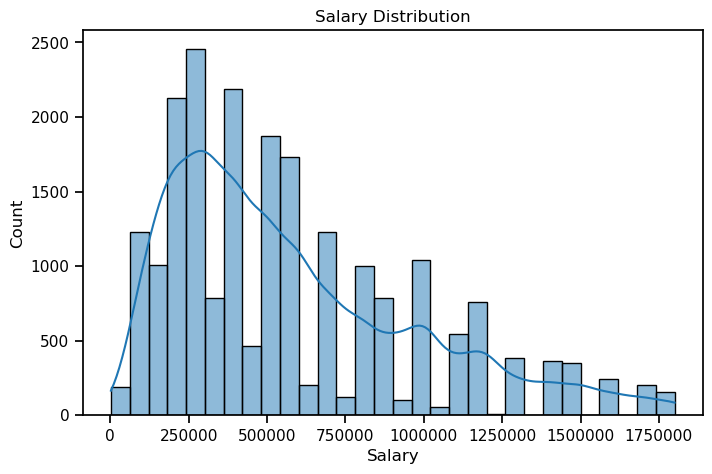

In [14]:
plt.figure(figsize=(8,5))
sns.histplot(df['Salary'], bins=30, kde=True)

plt.ticklabel_format(style='plain', axis='x')

plt.title('Salary Distribution')
plt.xlabel('Salary')
plt.ylabel('Count')
plt.show()

## Answering Basic Questions

### Q1: Which Job Roles have the Higest Average Salary

In [15]:
df

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android
...,...,...,...,...,...,...,...,...
22765,4.7,Expert Solutions,Web Developer,200000,1,Bangalore,Full Time,Web
22766,4.0,Nextgen Innovation Labs,Web Developer,300000,1,Bangalore,Full Time,Web
22767,4.1,Fresher,Full Stack Web Developer,192000,13,Bangalore,Full Time,Web
22768,4.1,Accenture,Full Stack Web Developer,300000,7,Bangalore,Full Time,Web


In [16]:
df['Job Roles'].nunique()

11

In [17]:
df['Job Roles'].unique()

array(['Android', 'Backend', 'Database', 'Frontend', 'IOS', 'Java',
       'Mobile', 'SDE', 'Python', 'Web', 'Testing'], dtype=object)

In [18]:
job_Salary = df.groupby('Job Roles')['Salary'].mean().sort_values(ascending=False)

job_Salary

Job Roles
Database    745670.833333
SDE         693104.775386
Mobile      648251.121076
IOS         617741.013470
Backend     574203.926740
Frontend    532927.754789
Android     501886.106443
Java        493755.957895
Testing     474144.130006
Python      460101.327641
Web         395296.404040
Name: Salary, dtype: float64

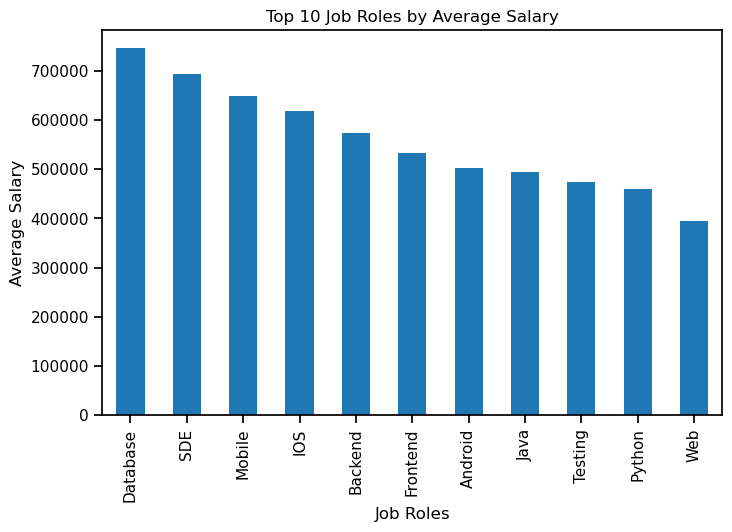

In [19]:
plt.figure(figsize = (8,5))
job_Salary.plot(kind='bar')
plt.title('Top 10 Job Roles by Average Salary')
plt.ylabel('Average Salary')
plt.show()

### Q2: Which Cities Offer Highest Average Salary?

In [20]:
df

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android
...,...,...,...,...,...,...,...,...
22765,4.7,Expert Solutions,Web Developer,200000,1,Bangalore,Full Time,Web
22766,4.0,Nextgen Innovation Labs,Web Developer,300000,1,Bangalore,Full Time,Web
22767,4.1,Fresher,Full Stack Web Developer,192000,13,Bangalore,Full Time,Web
22768,4.1,Accenture,Full Stack Web Developer,300000,7,Bangalore,Full Time,Web


In [21]:
city_salary = df.groupby('Location')['Salary'].mean().sort_values(ascending=False)

city_salary

Location
Mumbai            752751.976155
Bangalore         606592.401189
Pune              594584.661125
Hyderabad         571350.134149
Kolkata           566359.281437
Jaipur            566153.846154
New Delhi         564724.843308
Chennai           523388.068763
Kerala            514965.735849
Madhya Pradesh    505600.644295
Name: Salary, dtype: float64

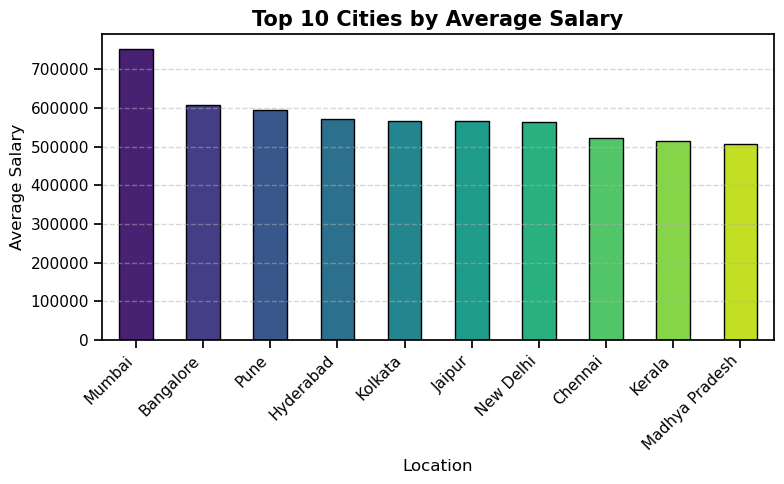

In [22]:
plt.figure(figsize = (8,5))
colors = sns.color_palette('viridis', len(city_salary))
city_salary.plot(kind='bar', color=colors, edgecolor='black')
plt.title('Top 10 Cities by Average Salary', fontsize=15, fontweight='bold')
plt.ylabel('Average Salary')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Q3: Name those 5 companies located in 'New Delhi' with Ratings of '5', offering the highest & lowest salaries.

In [23]:
df1= df[(df['Location'] == 'New Delhi') & (df['Rating']==5)].sort_values(by = 'Salary', ascending=False)

In [24]:
df1

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
18393,5.0,Firevol,Software Development Engineer (SDE),1700000,1,New Delhi,Full Time,SDE
6750,5.0,Hapramp,Front End Developer,1500000,1,New Delhi,Full Time,Frontend
17488,5.0,The Art of Mike Mignola,Software Development Engineer,1500000,1,New Delhi,Full Time,SDE
1888,5.0,Trillbit,Android Developer,1500000,1,New Delhi,Full Time,Android
8284,5.0,Silicon Valley Recycling,Senior IOS Developer,1400000,1,New Delhi,Full Time,IOS
...,...,...,...,...,...,...,...,...
8290,5.0,Rabbler,Senior IOS Developer Contractor,100000,1,New Delhi,Contractor,IOS
1969,5.0,WorkingNation,Android Developer - Intern,84000,1,New Delhi,Intern,Android
2334,5.0,Hopin (India),Android Developer - Intern,60000,1,New Delhi,Intern,Android
18680,5.0,Atom 8,Software Development Engineer (SDE) - Intern,60000,1,New Delhi,Intern,SDE


In [25]:
list(df1['Company Name'].head())

['Firevol',
 'Hapramp',
 'The Art of Mike Mignola',
 'Trillbit',
 'Silicon Valley Recycling']

In [26]:
list(df1['Company Name'].tail())

['Rabbler', 'WorkingNation', 'Hopin (India)', 'Atom 8', 'Star Catalysts']

### Q4: Which Job Title has the highest number of salary reported

In [27]:
df['Job Title'].value_counts()

Job Title
Software Development Engineer          2225
Android Developer                      1998
Software Development Engineer (SDE)    1528
Front End Developer                    1384
Test Engineer                          1301
                                       ... 
Head of Mobile Development                1
Junior Front-End Web Developer            1
Mobile Tester                             1
Full Stack Mobile Developer               1
Associate Web Developer                   1
Name: count, Length: 1014, dtype: int64

In [28]:
df.groupby('Job Title')['Salaries Reported'].count().sort_values(ascending=False)

Job Title
Software Development Engineer                 2225
Android Developer                             1998
Software Development Engineer (SDE)           1528
Front End Developer                           1384
Test Engineer                                 1301
                                              ... 
IOS Lead                                         1
React Native and Python Developer - Intern       1
React Js Front End Developer                     1
React Front End Developer                        1
Xamarin Mobile Developer                         1
Name: Salaries Reported, Length: 1014, dtype: int64

### Q5: Which 10 Companies provide the highest average salary, when at least 20 employees have reported their salaries

In [29]:
df

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android
...,...,...,...,...,...,...,...,...
22765,4.7,Expert Solutions,Web Developer,200000,1,Bangalore,Full Time,Web
22766,4.0,Nextgen Innovation Labs,Web Developer,300000,1,Bangalore,Full Time,Web
22767,4.1,Fresher,Full Stack Web Developer,192000,13,Bangalore,Full Time,Web
22768,4.1,Accenture,Full Stack Web Developer,300000,7,Bangalore,Full Time,Web


In [30]:
filtered_df= df[df['Salaries Reported'] >= 20]

filtered_df

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
8790,3.9,Tata Consultancy Services,Java Developer,200000,30,Chennai,Full Time,Java
8977,3.8,Cognizant Technology Solutions,Senior Java Developer,200000,35,Chennai,Full Time,Java
8978,3.9,Tata Consultancy Services,Senior Java Developer,300000,30,Chennai,Full Time,Java
8979,3.9,Tata Consultancy Services,Junior Java Developer,200000,30,Chennai,Full Time,Java
9688,3.9,Tata Consultancy Services,Java Developer,200000,43,Hyderabad,Full Time,Java
...,...,...,...,...,...,...,...,...
21762,3.8,CGI,Senior Test Engineer,400000,21,Bangalore,Full Time,Testing
21763,4.1,IBM,Test Automation Engineer,400000,21,Bangalore,Full Time,Testing
21764,3.7,SLK Group,Software Test Engineer,300000,20,Bangalore,Full Time,SDE
21765,4.3,Cisco Systems,Software Test Engineer,700000,20,Bangalore,Full Time,SDE


In [31]:
filtered_df.groupby('Company Name')['Salary'].mean().sort_values(ascending=False).head(10)

Company Name
Expedia Group        1.350000e+06
Cisco Systems        1.250000e+06
Amadeus              1.200000e+06
Nokia                1.200000e+06
Dell Technologies    1.000000e+06
Ola                  1.000000e+06
Alcatel-Lucent       1.000000e+06
Kony                 9.000000e+05
Lumen                9.000000e+05
Microsoft            7.845714e+05
Name: Salary, dtype: float64

### Q6: Check and show the relationship between Ratings and Salaries

In [32]:
df

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android
...,...,...,...,...,...,...,...,...
22765,4.7,Expert Solutions,Web Developer,200000,1,Bangalore,Full Time,Web
22766,4.0,Nextgen Innovation Labs,Web Developer,300000,1,Bangalore,Full Time,Web
22767,4.1,Fresher,Full Stack Web Developer,192000,13,Bangalore,Full Time,Web
22768,4.1,Accenture,Full Stack Web Developer,300000,7,Bangalore,Full Time,Web


In [33]:
df.corr(numeric_only=True)

,Rating,Salary,Salaries Reported
Rating,1.000000,0.028435,-0.012502
Salary,0.028435,1.000000,-0.021370
Salaries Reported,-0.012502,-0.021370,1.000000


In [34]:
df['Rating'].corr(df['Salary'])

np.float64(0.028435446014226973)

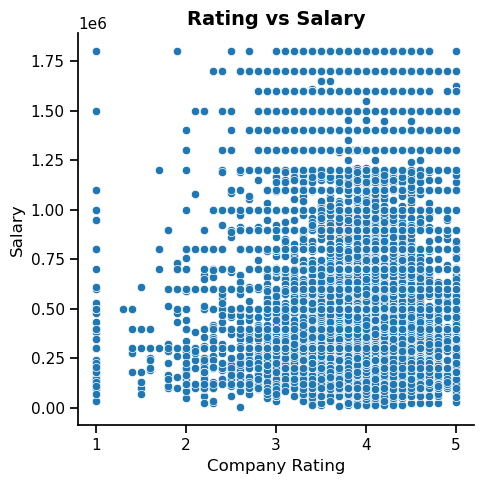

In [35]:
sns.relplot(x='Rating', y='Salary', data=df)
plt.title('Rating vs Salary', fontsize=14, fontweight='bold')
plt.xlabel('Company Rating')
plt.ylabel('Salary')
plt.tight_layout()
plt.show()

### Q7: Does employement Status affect salary?

In [36]:
df

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android
...,...,...,...,...,...,...,...,...
22765,4.7,Expert Solutions,Web Developer,200000,1,Bangalore,Full Time,Web
22766,4.0,Nextgen Innovation Labs,Web Developer,300000,1,Bangalore,Full Time,Web
22767,4.1,Fresher,Full Stack Web Developer,192000,13,Bangalore,Full Time,Web
22768,4.1,Accenture,Full Stack Web Developer,300000,7,Bangalore,Full Time,Web


In [37]:
df['Employment Status'].unique()

array(['Full Time', 'Intern', 'Contractor', 'Trainee'], dtype=object)

In [38]:
df['Employment Status'].value_counts()

Employment Status
Full Time     18966
Intern         2092
Contractor      523
Trainee          33
Name: count, dtype: int64

In [39]:
df.groupby('Employment Status')['Salary'].describe()

,count,mean,std,min,25%,50%,75%,max
Employment Status,,,,,,,,
Contractor,523.0,523849.697897,351437.182096,12000.0,300000.0,408000.0,678000.0,1800000.0
Full Time,18966.0,613544.648740,401432.268284,8448.0,300000.0,500000.0,876000.0,1800000.0
Intern,2092.0,340258.837476,268760.067534,2112.0,144000.0,276000.0,456000.0,1800000.0
Trainee,33.0,324303.030303,241096.516572,96000.0,144000.0,240000.0,400000.0,1100000.0


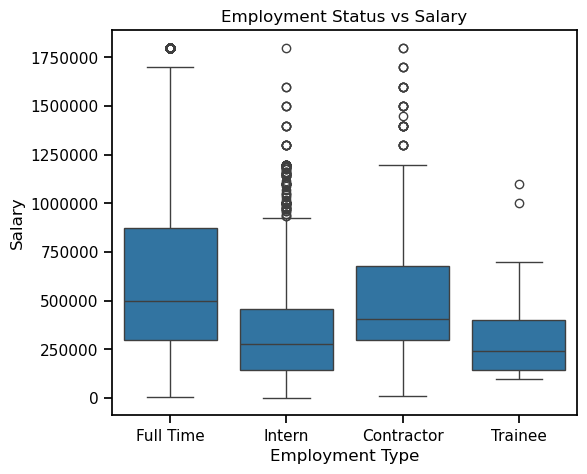

In [40]:
plt.figure(figsize=(6,5))
sns.boxplot(x='Employment Status', y='Salary', data=df)
plt.ticklabel_format(style='plain', axis='y')
plt.title('Employment Status vs Salary', fontsize=12)
plt.xlabel('Employment Type')
plt.ylabel('Salary')
plt.show()

### Q8: Which job roles are most common?

In [41]:
df

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android
...,...,...,...,...,...,...,...,...
22765,4.7,Expert Solutions,Web Developer,200000,1,Bangalore,Full Time,Web
22766,4.0,Nextgen Innovation Labs,Web Developer,300000,1,Bangalore,Full Time,Web
22767,4.1,Fresher,Full Stack Web Developer,192000,13,Bangalore,Full Time,Web
22768,4.1,Accenture,Full Stack Web Developer,300000,7,Bangalore,Full Time,Web


In [42]:
Top10 = df['Job Roles'].value_counts().head(10)

Top10

Job Roles
SDE         7573
Android     2856
Frontend    2088
Java        1805
Testing     1723
IOS         1559
Backend     1092
Web          990
Python       937
Database     768
Name: count, dtype: int64

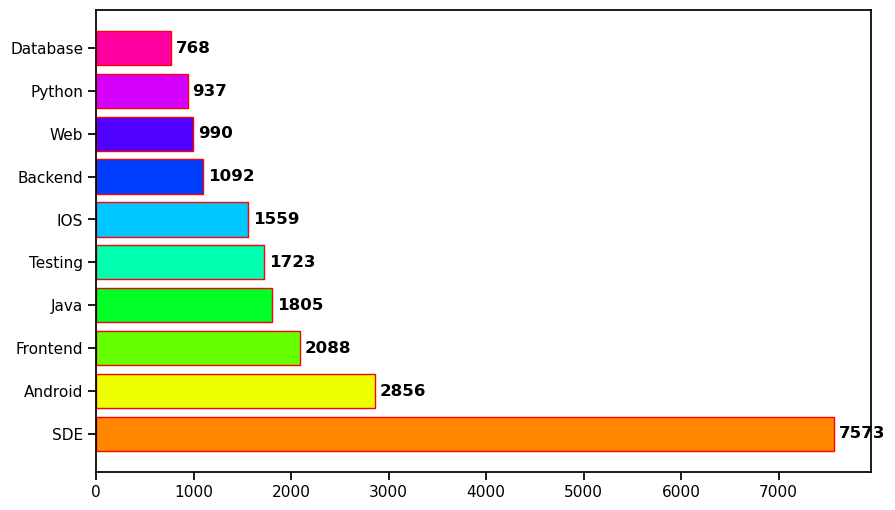

In [63]:
plt.figure(figsize=(10,6))
colors = sns.color_palette("hsv", len(Top10))
plt.barh(Top10.index, Top10.values, color=colors, edgecolor='red')
for i, v in enumerate(Top10.values):
    plt.text(v + 50, i, str(v), va = 'center', fontweight='bold')
plt.show()

### Q9: How does the average Salary Change as Company ratings increases

In [44]:
df

,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android
...,...,...,...,...,...,...,...,...
22765,4.7,Expert Solutions,Web Developer,200000,1,Bangalore,Full Time,Web
22766,4.0,Nextgen Innovation Labs,Web Developer,300000,1,Bangalore,Full Time,Web
22767,4.1,Fresher,Full Stack Web Developer,192000,13,Bangalore,Full Time,Web
22768,4.1,Accenture,Full Stack Web Developer,300000,7,Bangalore,Full Time,Web


In [47]:
rating_salary = df.groupby('Rating')['Salary'].mean().reset_index() #coverted series to dataframe
rating_salary

,Rating,Salary
0,1.00,421510.400000
1,1.30,500000.000000
2,1.40,331200.000000
3,1.50,241000.000000
4,1.60,262285.714286
5,1.70,750000.000000
6,1.80,330333.333333
7,1.90,543384.615385
8,2.00,437481.481481
9,2.10,465866.666667


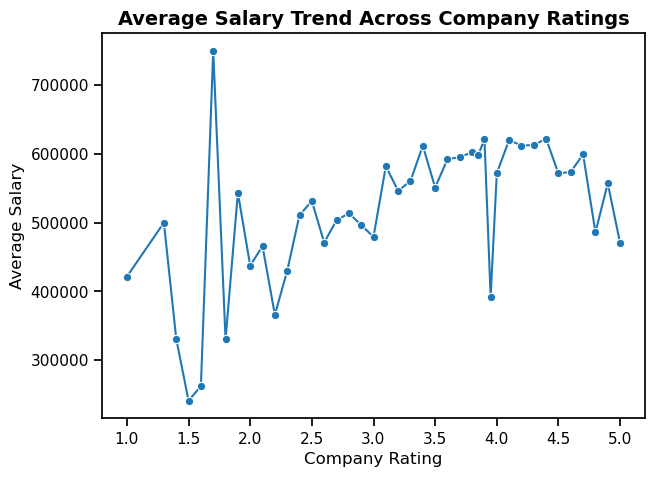

In [61]:
plt.figure(figsize=(7,5))
plt.title('Average Salary Trend Across Company Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Company Rating')
plt.ylabel('Average Salary')
sns.lineplot(x='Rating', y='Salary', data=rating_salary, marker='o')
plt.show()

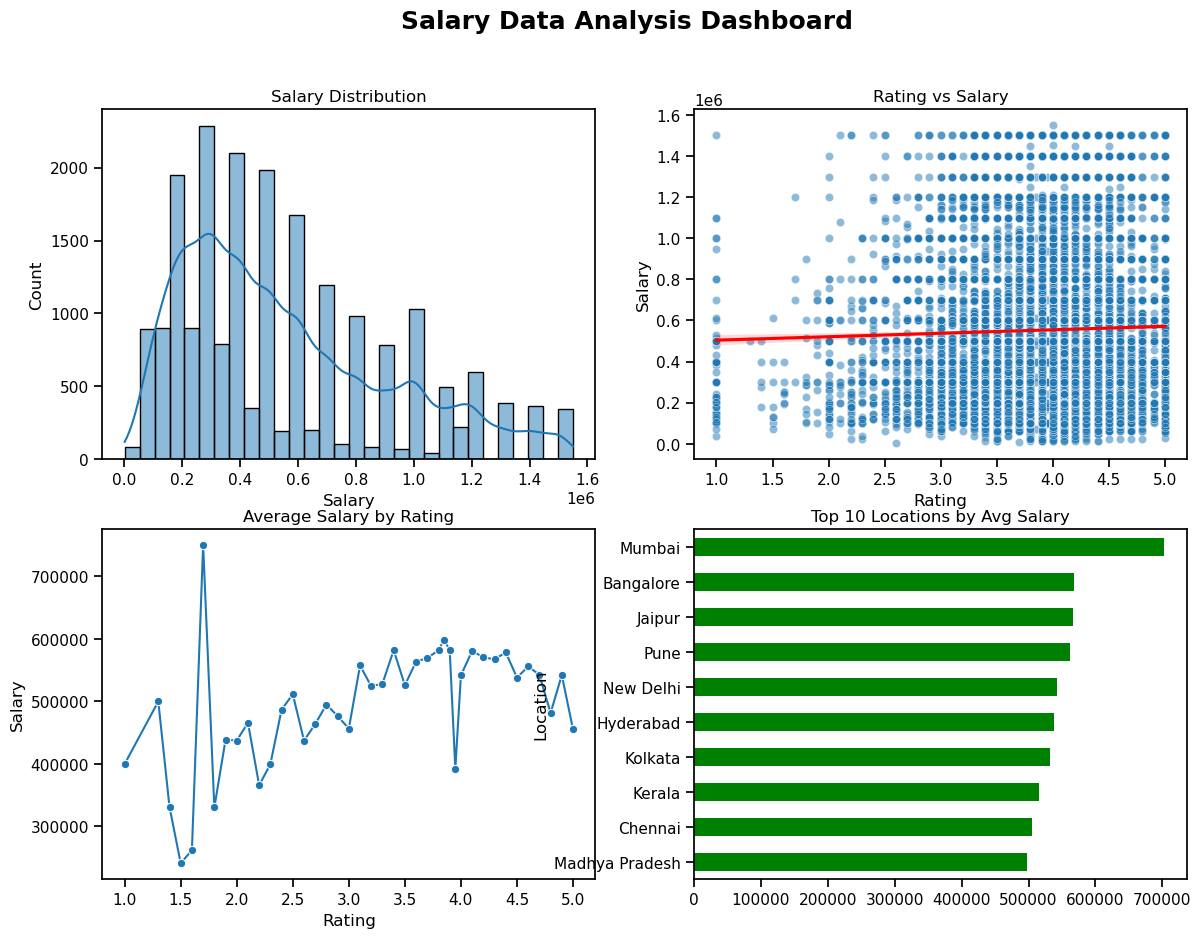

In [62]:
rating_salary = df.groupby('Rating')['Salary'].mean().reset_index()
top_locations = df.groupby('Location')['Salary'].mean().sort_values(ascending=False)

plt.figure(figsize=(14,10))

#1. Salary Distribution
plt.subplot(2,2,1)
sns.histplot(df['Salary'], bins = 30, kde=True)
plt.title('Salary Distribution')

#2. Rating vs Salary
plt.subplot(2,2,2)
sns.scatterplot(x='Rating', y='Salary', data=df, alpha=0.5)
sns.regplot(x='Rating', y='Salary', data=df, scatter=False, color='red')
plt.title('Rating vs Salary')

#3. Average Salary by Rating
plt.subplot(2,2,3)
sns.lineplot(x='Rating', y='Salary', data = rating_salary, marker = 'o')
plt.title('Average Salary by Rating')

#4. Top location for salary
plt.subplot(2,2,4)
top_locations.sort_values().plot(kind='barh', color='green')
plt.title('Top 10 Locations by Avg Salary')

plt.suptitle('Salary Data Analysis Dashboard', fontsize=18, fontweight='bold')
plt.show()